In [5]:
import torch
x = torch.tensor(2,dtype= torch.float32)
y = torch.tensor(5,dtype= torch.float32)
w = torch.tensor(3,dtype= torch.float32,requires_grad=True)
b = torch.tensor(0,dtype= torch.float32,requires_grad=True)
n = 0.2
loss_arr = []

with torch.no_grad():
    initial_loss = (x * w + b - y) ** 2
    loss_arr.append(initial_loss.item())

for step in range(200):
    w.grad = None
    b.grad = None
    y_predict = x * w + b
    loss = pow(y_predict - y , 2)
    loss.backward()
    with torch.no_grad():
        w -= w.grad * n 
        b -= b.grad * n
        y_predict = x * w + b
        loss = (y_predict - y) ** 2
        loss_arr.append(loss.item())

    print(f"Step {step + 1}: prediction={y_predict.item():.4f}, loss={loss.item():.6f}")



Step 1: prediction=4.0000, loss=1.000000
Step 2: prediction=6.0000, loss=1.000000
Step 3: prediction=4.0000, loss=1.000000
Step 4: prediction=6.0000, loss=1.000000
Step 5: prediction=4.0000, loss=1.000000
Step 6: prediction=6.0000, loss=1.000000
Step 7: prediction=4.0000, loss=1.000000
Step 8: prediction=6.0000, loss=1.000000
Step 9: prediction=4.0000, loss=1.000000
Step 10: prediction=6.0000, loss=1.000000
Step 11: prediction=4.0000, loss=1.000000
Step 12: prediction=6.0000, loss=1.000000
Step 13: prediction=4.0000, loss=1.000000
Step 14: prediction=6.0000, loss=1.000000
Step 15: prediction=4.0000, loss=1.000000
Step 16: prediction=6.0000, loss=1.000000
Step 17: prediction=4.0000, loss=1.000000
Step 18: prediction=6.0000, loss=1.000000
Step 19: prediction=4.0000, loss=1.000000
Step 20: prediction=6.0000, loss=1.000000
Step 21: prediction=4.0000, loss=1.000000
Step 22: prediction=6.0000, loss=1.000000
Step 23: prediction=4.0000, loss=1.000000
Step 24: prediction=6.0000, loss=1.000000
S

将学习率从 0.001 增大到 0.01 后，loss 更快接近零；增大到 0.2 后，预测值在 4 和 6 之间振荡，loss 保持为 1。梯度提供局部下降方向，但过大的更新步长可能使模型越过合适的位置，无法收敛。

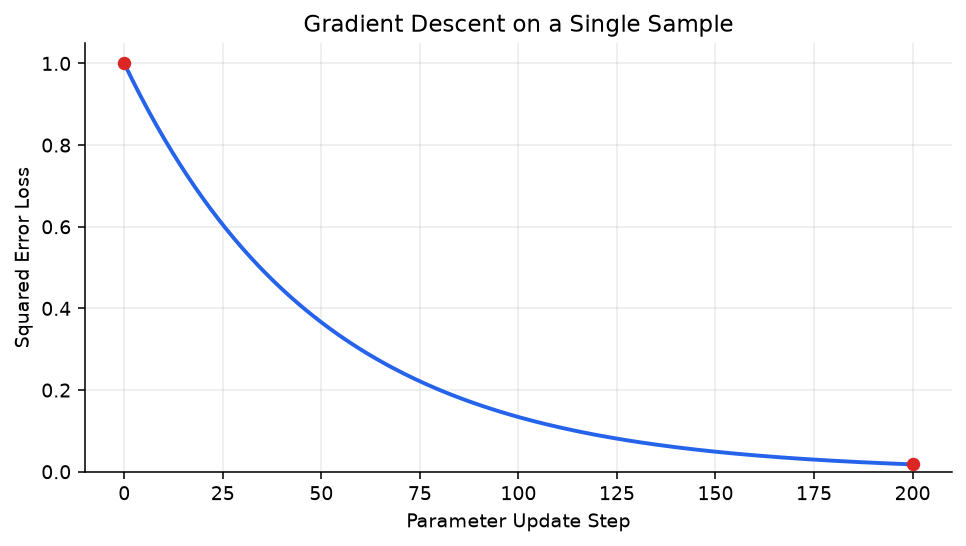

Recorded states: 201
Initial loss: 1.000000
Final loss:   0.017950


In [2]:
import matplotlib.pyplot as plt

steps = range(len(loss_arr))

fig, ax = plt.subplots(figsize=(7, 4), dpi=140)

ax.plot(steps, loss_arr, color="#2563EB", linewidth=2)
ax.scatter(
    [0, len(loss_arr) - 1],
    [loss_arr[0], loss_arr[-1]],
    color="#DC2626",
    s=35,
    zorder=3,
)

ax.set(
    title="Gradient Descent on a Single Sample",
    xlabel="Parameter Update Step",
    ylabel="Squared Error Loss",
)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Recorded states: {len(loss_arr)}")
print(f"Initial loss: {loss_arr[0]:.6f}")
print(f"Final loss:   {loss_arr[-1]:.6f}")